# Do Free Sample Kits Really Increase Clinic Sales? A Causal Analysis of 3,500 Clinics in Japan

### Executive Summary

In B2B medical marketing, sales teams often distribute free sample kits to doctors. In this project, I evaluate whether sample kits actually increased clinic purchases across 3,500 clinics in Japan over 36 months (2021 to 2023). I analyzed four products: BrandA, BrandB, BrandC, and BrandD. I used Difference-in-Differences and Two-Way Fixed Effects to control for clinic differences and monthly market trends.

#### Key Findings

| Brand | Naive difference | Uplift from TWFE (units/clinic/month) | Significant? | Recommendation |
|:---|:---:|:---:|:---:|:---|
| **BrandA** | +38.65 units | **+40.33 units / month** | Yes (p < 0.0001) | Keep and expand sampling |
| **BrandB** | +0.91 units | **+0.08 units / month** | No (p = 0.2071) | Stop sampling (no measurable effect) |
| **BrandC** | +0.86 units | **+0.03 units / month** | No (p = 0.7219) | Stop sampling; review why reps send kits after order drops |
| **BrandD** | +1.03 units | **+2.42 units / month** | Yes (p < 0.0001) | Sample only clinics that already buy BrandD |

Notes:
- For BrandC, running the model without marking the sales dip gives a fake uplift of +2.62 units per month. Marking the dip shows the real effect is about zero.
- For BrandD, the overall uplift of +2.42 units is an average. On existing buyers, the uplift is +4.91 units per month. On prospect clinics that never bought BrandD, the uplift is 0.00.
- All recommendations use illustrative cost and margin assumptions explained in Section 9.

## 1. Setup & Load Data

I start by importing standard Python libraries and helper functions from `did_helpers`. I also configure the chart display settings.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Add project root to sys.path
for p in ['.', '..']:
    if os.path.exists(os.path.join(p, 'src', 'did_helpers.py')):
        if p not in sys.path:
            sys.path.insert(0, p)
        DATA_PATH = os.path.join(p, 'data', 'fact_clinic_month.csv')
        FIG_DIR = os.path.join(p, 'figures')
        break

from src.did_helpers import add_relative_month, check_balanced_panel, run_simple_twfe

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10

Next, I load the panel dataset and add the `rel_month` column. This column tracks elapsed months relative to sample kit delivery (0 is the trial month, negative is before, positive is after).

In [2]:
df = pd.read_csv(DATA_PATH)
df = add_relative_month(df)

print(f"Total rows: {df.shape[0]:,}")
print(f"Total columns: {df.shape[1]}")
df.head(3)

Total rows: 504,000
Total columns: 13


,month,clinic_id,brand,region,clinic_size,channel,trial_qty,sales_qty,sales_recurring_qty,sales_nonrecurring_qty,active_customer_flag,first_trial_month,rel_month
0,2021-01,C00001,BrandA,Kanto,Small,Direct,0,8,6,2,1,2022-11,-22.0
1,2021-01,C00001,BrandB,Kanto,Small,Direct,0,21,18,3,1,NaN,NaN
2,2021-01,C00001,BrandC,Kanto,Small,Direct,0,16,14,2,1,2022-07,-18.0


The dataset contains 504,000 monthly records across 3,500 clinics, 36 calendar months, and 4 brands. For clinics that never received a sample kit, `rel_month` is `NaN`.

## 2. Data Health Check

I run two quick data checks: confirming that rows are unique across clinic, month, and brand, and verifying that recurring plus non-recurring sales equals total sales.

In [3]:
duplicates = df.duplicated(subset=['month', 'clinic_id', 'brand']).sum()
sales_adds_up = (df['sales_qty'] == df['sales_recurring_qty'] + df['sales_nonrecurring_qty']).all()

print(f"Duplicate rows: {duplicates}")
print(f"Sales additivity check passed: {sales_adds_up}")

Duplicate rows: 0
Sales additivity check passed: True


I also confirm that each brand has a balanced panel of 36 months per clinic, and I check how many clinics received sample kits.

In [4]:
counts = []
for b in ['BrandA', 'BrandB', 'BrandC', 'BrandD']:
    sub = df[df['brand'] == b]
    check_balanced_panel(sub, expected_months=36)
    n_treated = sub[sub['first_trial_month'].notna()]['clinic_id'].nunique()
    n_control = sub[sub['first_trial_month'].isna()]['clinic_id'].nunique()
    counts.append({'Brand': b, 'Treated': n_treated, 'Control': n_control, 'Total': n_treated + n_control})

pd.DataFrame(counts)

,Brand,Treated,Control,Total
0,BrandA,1218,2282,3500
1,BrandB,1220,2280,3500
2,BrandC,1191,2309,3500
3,BrandD,1245,2255,3500


All 3,500 clinics have all 36 months for every brand. About 1,200 clinics received sample kits per brand, leaving about 2,300 clinics as a control pool.

## 3. Quick Exploratory Data Analysis (EDA)

I examine three basic patterns in the data: monthly sales over calendar time, sales by clinic size, and the share of clinics that never bought BrandD.

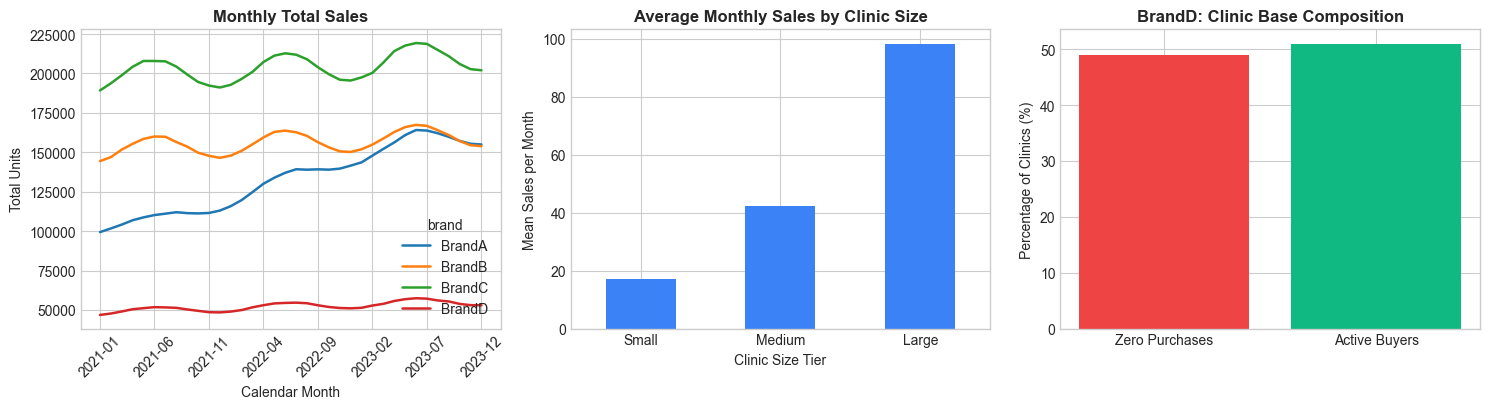

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# 1. Monthly sales trend
monthly = df.groupby(['month', 'brand'])['sales_qty'].sum().unstack()
monthly.plot(ax=axes[0], linewidth=1.8)
axes[0].set_title('Monthly Total Sales', fontweight='bold')
axes[0].set_xlabel('Calendar Month')
axes[0].set_ylabel('Total Units')
axes[0].tick_params(axis='x', rotation=45)

# 2. Average monthly sales by clinic size
size_order = ['Small', 'Medium', 'Large']
size_avg = df.groupby('clinic_size')['sales_qty'].mean().reindex(size_order)
size_avg.plot(kind='bar', ax=axes[1], color='#3b82f6')
axes[1].set_title('Average Monthly Sales by Clinic Size', fontweight='bold')
axes[1].set_xlabel('Clinic Size Tier')
axes[1].set_ylabel('Mean Sales per Month')
axes[1].tick_params(axis='x', rotation=0)

# 3. Share of clinics with zero purchases for BrandD
b_d_totals = df[df['brand'] == 'BrandD'].groupby('clinic_id')['sales_qty'].sum()
zero_pct = (b_d_totals == 0).mean() * 100
axes[2].bar(['Zero Purchases', 'Active Buyers'], [zero_pct, 100 - zero_pct], color=['#ef4444', '#10b981'])
axes[2].set_title('BrandD: Clinic Base Composition', fontweight='bold')
axes[2].set_ylabel('Percentage of Clinics (%)')

plt.tight_layout()
plt.show()

How to read these charts:
1. Left chart: Sales show regular seasonality and slow growth over time. This means I need to control for month effects.
2. Middle chart: Large clinics sell about 98 units per month on average, compared to 42 for medium and 17 for small. I need clinic fixed effects so large clinics are not compared directly with small ones.
3. Right chart: 49.0% of clinics never bought BrandD in the entire 36-month period. I examine this in Section 8b.

## 4. Are Treated and Control Clinics Similar?

To see whether sales reps picked bigger clinics for sample kits, I compare treated and control clinics during the months before any clinic received a sample kit.

In [6]:
balance_rows = []
for b in ['BrandA', 'BrandB', 'BrandC', 'BrandD']:
    sub = df[df['brand'] == b]
    earliest_trial = sub['first_trial_month'].dropna().min()
    pre_sub = sub[sub['month'] < earliest_trial]
    
    t_ids = sub[sub['first_trial_month'].notna()]['clinic_id'].unique()
    c_ids = sub[sub['first_trial_month'].isna()]['clinic_id'].unique()
    
    t_sales = pre_sub[pre_sub['clinic_id'].isin(t_ids)]['sales_qty'].mean()
    c_sales = pre_sub[pre_sub['clinic_id'].isin(c_ids)]['sales_qty'].mean()
    diff_pct = ((t_sales - c_sales) / c_sales) * 100
    
    t_large = (sub[sub['clinic_id'].isin(t_ids)].drop_duplicates('clinic_id')['clinic_size'] == 'Large').mean() * 100
    c_large = (sub[sub['clinic_id'].isin(c_ids)].drop_duplicates('clinic_id')['clinic_size'] == 'Large').mean() * 100
    
    balance_rows.append({
        'Brand': b,
        'Earliest Trial': earliest_trial,
        'Treated Pre Avg': round(t_sales, 2),
        'Control Pre Avg': round(c_sales, 2),
        'Difference (%)': f"{diff_pct:+.2f}%",
        'Treated % Large': f"{t_large:.1f}%",
        'Control % Large': f"{c_large:.1f}%"
    })

pd.DataFrame(balance_rows)

,Brand,Earliest Trial,Treated Pre Avg,Control Pre Avg,Difference (%),Treated % Large,Control % Large
0,BrandA,2021-05,29.72,29.29,+1.45%,17.7%,16.1%
1,BrandB,2021-05,42.81,42.72,+0.23%,16.4%,16.8%
2,BrandC,2021-07,57.48,57.12,+0.63%,17.0%,16.5%
3,BrandD,2021-05,13.24,14.21,-6.80%,17.0%,16.5%


Before any samples were sent, treated and control clinics look very similar:
- For BrandA, BrandB, and BrandC, average pre-trial sales differ by only +0.23% to +1.45%.
- For BrandD, treated clinics sold slightly less (-6.80%).
- The share of large clinics is close across all brands (about 16% to 18% in both groups).

In this data, sales reps did not obviously pick larger clinics. The main analytical challenges are timing (when samples were delivered) and customer types (active buyers versus prospects), which I explore next.

## 5. The Correlation Trap: Why Naive Comparisons Mislead

A common starting point in commercial analysis is comparing average sales of treated clinics after receiving samples against control clinics. Here I calculate that gap and also compare against control clinics in the exact same calendar months.

In [7]:
naive_rows = []
for b in ['BrandA', 'BrandB', 'BrandC', 'BrandD']:
    sub = df[df['brand'] == b]
    treated_post = sub[sub['rel_month'] >= 1]
    post_months = treated_post['month'].unique()
    
    t_post_avg = treated_post['sales_qty'].mean()
    c_all_avg = sub[sub['first_trial_month'].isna()]['sales_qty'].mean()
    c_same_avg = sub[(sub['first_trial_month'].isna()) & (sub['month'].isin(post_months))]['sales_qty'].mean()
    
    naive_rows.append({
        'Brand': b,
        'Treated Post Avg': round(t_post_avg, 2),
        'Control All-Months Avg': round(c_all_avg, 2),
        'Control Same-Months Avg': round(c_same_avg, 2),
        'Naive Gap (vs All)': round(t_post_avg - c_all_avg, 2),
        'Gap (vs Same Months)': round(t_post_avg - c_same_avg, 2)
    })

naive_df = pd.DataFrame(naive_rows)
naive_df

,Brand,Treated Post Avg,Control All-Months Avg,Control Same-Months Avg,Naive Gap (vs All),Gap (vs Same Months)
0,BrandA,69.20,30.55,30.70,38.65,38.50
1,BrandB,45.47,44.55,44.77,0.91,0.70
2,BrandC,59.16,58.30,58.50,0.86,0.65
3,BrandD,15.84,14.81,14.89,1.03,0.95


What this table shows:
1. BrandA: The naive gap is +38.65 units. This mixes in the first post-trial month when sales have not started climbing yet.
2. BrandB and BrandC: Comparing against all control months shows small positive gaps (+0.91 and +0.86 units). When I compare against control clinics in the same calendar months, the gaps shrink to +0.70 and +0.65. This shows that part of the naive gap comes from calendar timing, because post-trial periods happen later when market sales are slightly higher.
3. BrandD: The naive gap is +1.03 units. This mixes active buyers with clinics that never buy.

To separate true sample effects from timing and clinic baselines, I use Difference-in-Differences.

## 6. Difference-in-Differences & Dynamic Event Study

The idea behind Difference-in-Differences (DiD) is simple:
- Clinic A (received sample): sales grew from 30 to 50 units (+20 units).
- Clinic B (no sample, same months): sales grew from 30 to 35 units (+5 units, market trend).
- Estimated causal impact: 20 minus 5 = +15 units.

To verify DiD, I plot an event study. The line shows the difference between treated and control clinics relative to month -2 (two months before sample delivery). If pre-trends are parallel, the line should stay near zero before month 0.

In [8]:
# Compute event study data for each brand
event_study_data = {}
for b in ['BrandA', 'BrandB', 'BrandC', 'BrandD']:
    sub = df[df['brand'] == b].copy()
    control_benchmark = sub[sub['first_trial_month'].isna()].groupby('month')['sales_qty'].mean()
    sub['benchmark'] = sub['month'].map(control_benchmark)
    sub['diff_vs_control'] = sub['sales_qty'] - sub['benchmark']
    
    window = sub[(sub['rel_month'] >= -6) & (sub['rel_month'] <= 12)].copy()
    baseline = window[window['rel_month'] == -2].groupby('clinic_id')['diff_vs_control'].first()
    window = window[window['clinic_id'].isin(baseline.index)].copy()
    window['did_effect'] = window['diff_vs_control'] - window['clinic_id'].map(baseline)
    
    es = window.groupby('rel_month')['did_effect'].agg(['mean', 'sem']).reset_index()
    event_study_data[b] = es

Now I plot the event study across all four brands and save the chart.

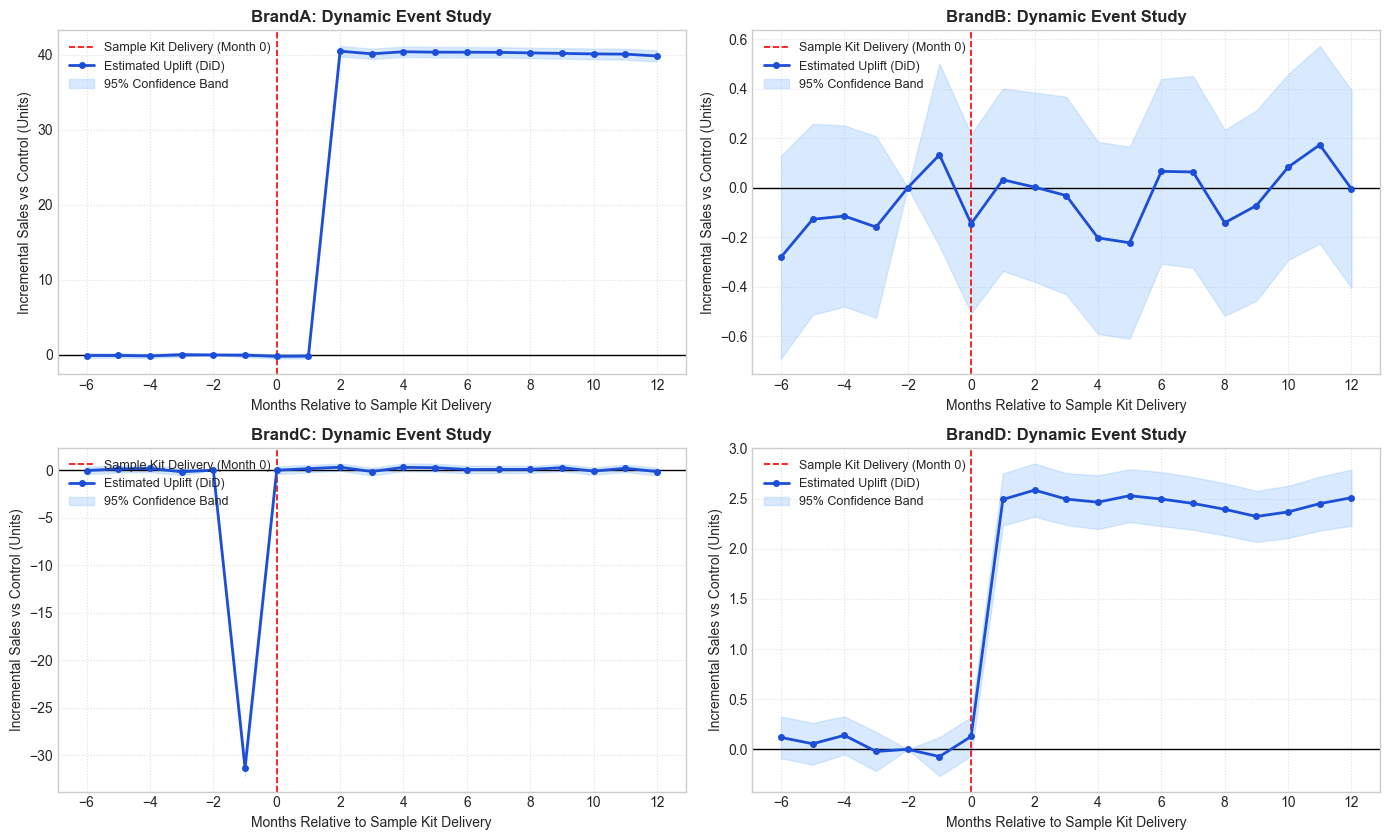

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8.5), sharey=False)
axes = axes.flatten()

for i, b in enumerate(['BrandA', 'BrandB', 'BrandC', 'BrandD']):
    es = event_study_data[b]
    ax = axes[i]
    ax.axhline(0, color='black', linestyle='-', linewidth=1)
    ax.axvline(0, color='red', linestyle='--', linewidth=1.2, label='Sample Kit Delivery (Month 0)')
    ax.plot(es['rel_month'], es['mean'], marker='o', markersize=4, color='#1d4ed8', linewidth=2, label='Estimated Uplift (DiD)')
    ax.fill_between(es['rel_month'], es['mean'] - 1.96 * es['sem'], es['mean'] + 1.96 * es['sem'],
                    color='#93c5fd', alpha=0.35, label='95% Confidence Band')
    ax.set_title(f'{b}: Dynamic Event Study', fontsize=12, fontweight='bold')
    ax.set_xlabel('Months Relative to Sample Kit Delivery')
    ax.set_ylabel('Incremental Sales vs Control (Units)')
    ax.set_xticks(range(-6, 13, 2))
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper left', fontsize=9)

plt.tight_layout()
os.makedirs(FIG_DIR, exist_ok=True)
plt.savefig(os.path.join(FIG_DIR, 'event_study_by_brand.png'), dpi=300)
plt.show()

How to read this chart:
1. Months -6 to -2: The line stays close to zero for all four brands. This indicates that treated and control clinics followed similar trends before sample kits were delivered.
2. BrandA: Flat at months 0 and 1, then jumps to about +40 units at month 2 and stays there. There is an adoption delay of two months.
3. BrandB: Moves around zero throughout. The shaded 95% band always includes zero, showing no clear effect.
4. BrandC: Drops by about -31 units at month -1, then returns to near zero from month 0 onwards. There is no lasting gain above baseline.
5. BrandD: Jumps to about +2.5 units at month 1 and remains steady.

## 7. Two-Way Fixed Effects (TWFE) & The Brand C Trap

Two-Way Fixed Effects controls for clinic differences and monthly market trends. Because the panel is balanced, I can run it by subtracting each clinic's average and each month's average (called demeaning) and running OLS with clustered standard errors.

I set the adoption onset based on the event study chart: month 2 for BrandA (due to the delay) and month 1 for the other brands.

In [10]:
twfe_summary = []
for b in ['BrandA', 'BrandB', 'BrandC', 'BrandD']:
    sub = df[df['brand'] == b].copy()
    check_balanced_panel(sub)
    onset = 2 if b == 'BrandA' else 1
    sub['is_post_trial'] = np.where(sub['rel_month'] >= onset, 1, 0)
    
    if b == 'BrandC':
        sub['dip_window'] = np.where(sub['rel_month'].isin([-1, 0]), 1, 0)
        coef, se, pval = run_simple_twfe(sub, 'sales_qty', ['is_post_trial', 'dip_window'])
    else:
        coef, se, pval = run_simple_twfe(sub, 'sales_qty', 'is_post_trial')
        
    ci_low = coef - 1.96 * se
    ci_high = coef + 1.96 * se
    twfe_summary.append({
        'Brand': b, 'Onset Month': onset,
        'Causal Uplift (Units / Month)': round(coef, 2),
        'Std. Error': round(se, 2),
        '95% Confidence Interval': f"[{round(ci_low, 2)}, {round(ci_high, 2)}]",
        'p-value': round(pval, 4),
        'Significant?': 'Yes' if pval < 0.05 else 'No'
    })

twfe_df = pd.DataFrame(twfe_summary)
twfe_df

,Brand,Onset Month,Causal Uplift (Units / Month),Std. Error,95% Confidence Interval,p-value,Significant?
0,BrandA,2,40.33,0.33,"[39.69, 40.96]",0.0000,Yes
1,BrandB,1,0.08,0.07,"[-0.05, 0.21]",0.2071,No
2,BrandC,1,0.03,0.07,"[-0.12, 0.17]",0.7219,No
3,BrandD,1,2.42,0.09,"[2.23, 2.6]",0.0000,Yes


Now I demonstrate why marking the dip matters for BrandC. I run BrandC without the dip marker and compare the two results side by side.

In [11]:
sub_c = df[df['brand'] == 'BrandC'].copy()
sub_c['is_post_trial'] = np.where(sub_c['rel_month'] >= 1, 1, 0)
sub_c['dip_window'] = np.where(sub_c['rel_month'].isin([-1, 0]), 1, 0)

coef_c_raw, se_c_raw, pval_c_raw = run_simple_twfe(sub_c, 'sales_qty', 'is_post_trial')
coef_c_clean, se_c_clean, pval_c_clean = run_simple_twfe(sub_c, 'sales_qty', ['is_post_trial', 'dip_window'])

pd.DataFrame([
    {'Model': 'BrandC without dip marker', 'Uplift': round(coef_c_raw, 2), 'Std. Error': round(se_c_raw, 2), 'p-value': round(pval_c_raw, 4)},
    {'Model': 'BrandC with dip marker', 'Uplift': round(coef_c_clean, 2), 'Std. Error': round(se_c_clean, 2), 'p-value': round(pval_c_clean, 4)}
])

,Model,Uplift,Std. Error,p-value
0,BrandC without dip marker,2.62,0.09,0.0000
1,BrandC with dip marker,0.03,0.07,0.7219


Without the dip marker, BrandC looks like it gained +2.62 units per month (p < 0.0001). That number is misleading. The month before the sample kit had an acute drop in orders, which pulled down the pre-sample average. After the sample arrived, sales naturally reverted to baseline, making the post-sample period look like an increase. Once I mark the dip separately, the estimated uplift is only +0.03 units per month (p = 0.7219).

These TWFE estimates align with the flat parts of the event study chart: BrandA around 40 units, BrandD around 2.5 units, and BrandB and BrandC around 0 units.

## 8. Thorough Analysis

### 8a. BrandB: Same Result in Percent Terms?

BrandB showed no clear effect in unit terms. As a check, I estimate the change in percent using `log(1 + sales_qty)`. If sample kits did not change purchasing behavior, the percent change should also be close to zero.

In [1]:
sub_b = df[df['brand'] == 'BrandB'].copy()
check_balanced_panel(sub_b)

sub_b['log_sales'] = np.log1p(sub_b['sales_qty'])
sub_b['is_post_trial'] = np.where(sub_b['rel_month'] >= 1, 1, 0)

coef_b_log, se_b_log, pval_b_log = run_simple_twfe(sub_b, 'log_sales', 'is_post_trial')
pct_uplift = coef_b_log * 100

print(f"BrandB percent uplift: {pct_uplift:+.2f}%")
print(f"Standard error: {se_b_log * 100:.2f}%")
print(f"p-value: {pval_b_log:.4f}")

NameError: name 'df' is not defined

In percent terms, the uplift is +0.22% with a p-value of 0.3904. This matches the unit analysis: there is no measurable change in sales after receiving sample kits.

### 8b. BrandD: Existing Buyers vs. Prospects

In Section 3, I observed that 49.0% of clinics had zero total sales for BrandD. I split clinics into two groups based on whether they bought BrandD before the first trial rollout in May 2021:
- Existing buyers: bought BrandD at least once before May 2021 (1,785 clinics).
- Prospects: zero purchases before May 2021 (1,715 clinics).

In [ ]:
sub_d = df[df['brand'] == 'BrandD'].copy()
min_trial = sub_d['first_trial_month'].dropna().min()

pre_sales = sub_d[sub_d['month'] < min_trial].groupby('clinic_id')['sales_qty'].sum()
existing_ids = pre_sales[pre_sales > 0].index
prospect_ids = pre_sales[pre_sales == 0].index

# 1. Existing buyers TWFE
sub_d_exist = sub_d[sub_d['clinic_id'].isin(existing_ids)].copy()
check_balanced_panel(sub_d_exist)
sub_d_exist['is_post_trial'] = np.where(sub_d_exist['rel_month'] >= 1, 1, 0)
coef_d_ex, se_d_ex, pval_d_ex = run_simple_twfe(sub_d_exist, 'sales_qty', 'is_post_trial')

# 2. Prospects check
sub_d_prosp = sub_d[sub_d['clinic_id'].isin(prospect_ids)].copy()
prospect_total_sales = sub_d_prosp['sales_qty'].sum()

pd.DataFrame([
    {'Segment': 'Existing Buyers', 'Clinics': len(existing_ids), 'Result': f"Uplift +{coef_d_ex:.2f} units/month (p < 0.0001)"},
    {'Segment': 'Prospect Clinics', 'Clinics': len(prospect_ids), 'Result': f"0 units bought across all 36 months (Total: {prospect_total_sales})"}
])

,Segment,Clinics,Result
0,Existing Buyers,1785,Uplift +4.91 units/month (p < 0.0001)
1,Prospect Clinics,1715,0 units bought across all 36 months (Total: 0)


This split explains the overall +2.42 units result for BrandD:
- For clinics that already buy BrandD, sample kits generated an extra +4.91 units per month (p < 0.0001).
- For prospect clinics, sales remained at 0 in every month, before and after receiving samples.

Sending BrandD sample kits to clinics that never bought the product did not generate any sales in this data.

## 9. Break-Even Analysis

To evaluate whether sampling costs pay back, I calculate a simple break-even threshold using illustrative assumptions:
- Profit margin: 1,500 JPY per unit sold.
- Sample kit cost: 12,000 JPY per kit delivered.
- Payback horizon: 12 months after delivery.

The break-even uplift needed to recover kit cost is:
12,000 JPY / (1,500 JPY * 12 months) = 0.67 units per clinic per month.

In [14]:
be_target = 12000 / (1500 * 12)

eval_cases = [
    ('BrandA (Overall)', twfe_summary[0]['Causal Uplift (Units / Month)'], twfe_summary[0]['p-value']),
    ('BrandB (Overall)', twfe_summary[1]['Causal Uplift (Units / Month)'], twfe_summary[1]['p-value']),
    ('BrandC (With dip marker)', twfe_summary[2]['Causal Uplift (Units / Month)'], twfe_summary[2]['p-value']),
    ('BrandD (Existing Buyers)', round(coef_d_ex, 2), pval_d_ex),
    ('BrandD (Prospects)', 0.00, 1.0)
]

be_rows = []
for name, uplift, pval in eval_cases:
    is_sig = pval < 0.05
    pays_back = 'Yes' if (is_sig and uplift >= be_target) else 'No (no proven effect)' if not is_sig else 'No'
    margin_12m = uplift * 1500 * 12 if is_sig else 0.0
    
    be_rows.append({
        'Brand / Segment': name,
        'Estimated Uplift (units/mo)': uplift,
        'Break-Even Target (units/mo)': round(be_target, 2),
        'Significant?': 'Yes' if is_sig else 'No',
        'Pays Back?': pays_back,
        '12-Month Est. Margin (JPY)': f"{margin_12m:,.0f} JPY"
    })

be_df = pd.DataFrame(be_rows)
be_df

,Brand / Segment,Estimated Uplift (units/mo),Break-Even Target (units/mo),Significant?,Pays Back?,12-Month Est. Margin (JPY)
0,BrandA (Overall),40.33,0.67,Yes,Yes,"725,940 JPY"
1,BrandB (Overall),0.08,0.67,No,No (no proven effect),0 JPY
2,BrandC (With dip marker),0.03,0.67,No,No (no proven effect),0 JPY
3,BrandD (Existing Buyers),4.91,0.67,Yes,Yes,"88,380 JPY"
4,BrandD (Prospects),0.00,0.67,No,No (no proven effect),0 JPY


Summary of recommendations:
1. BrandA: At +40.33 units per month, the uplift is well above the 0.67 break-even target. I recommend keeping and expanding sample distribution for BrandA.
2. BrandB: The estimated uplift is +0.08 units per month and is not statistically significant. I recommend stopping sample kits for BrandB.
3. BrandC: After accounting for the order dip, the uplift is +0.03 units per month and not statistically significant. I recommend stopping sample kits and reviewing why reps send kits following cancellations.
4. BrandD: For existing buyers, +4.91 units per month easily clears the break-even target. For prospects, conversion was zero. I recommend sampling only clinics that already buy BrandD.

## 10. Limitations

I note several limitations of this analysis:
- Samples were not distributed through a randomized A/B trial. I rely on treated and control clinics following parallel paths before sample delivery, which I verified visually in the event study chart.
- Pre-trends were checked visually from charts rather than with a formal statistical test.
- Clinics received sample kits in different months. When treatment effects change over time, standard Two-Way Fixed Effects can carry bias. In this data, event study lines remain flat after the initial shift, which reduces this concern. The archive folder contains earlier notes on advanced methods.
- The dataset is synthetic. Real commercial data would likely have more noise and missing entries.
- The financial calculations depend on the illustrative cost and margin assumptions.

## Appendix: Are the Estimates Close to the True Values?

Because this dataset was created using a synthetic data generator script, the true parameters are known. I compare the empirical estimates against those settings to verify accuracy.

In [15]:
# True settings from data_generator_script.py (0.60 and 0.10 elasticity parameters)
mean_trial_A = df[(df['brand'] == 'BrandA') & (df['trial_qty'] > 0)]['trial_qty'].mean()
mean_trial_D = sub_d_exist[sub_d_exist['trial_qty'] > 0]['trial_qty'].mean()

check_rows = [
    ('BrandA (Overall)', 0.60 * mean_trial_A, twfe_summary[0]['Causal Uplift (Units / Month)'], twfe_summary[0]['Std. Error']),
    ('BrandB (Overall)', 0.00, twfe_summary[1]['Causal Uplift (Units / Month)'], twfe_summary[1]['Std. Error']),
    ('BrandC (With dip marker)', 0.00, twfe_summary[2]['Causal Uplift (Units / Month)'], twfe_summary[2]['Std. Error']),
    ('BrandD (Existing Buyers)', 0.10 * mean_trial_D, round(coef_d_ex, 2), round(se_d_ex, 2))
]

validation_table = []
for name, true_val, est_val, se_val in check_rows:
    ci_l, ci_h = est_val - 1.96 * se_val, est_val + 1.96 * se_val
    validation_table.append({
        'Brand / Segment': name,
        'True Value': round(true_val, 2),
        'Estimated Uplift': round(est_val, 2),
        '95% CI': f"[{ci_l:.2f}, {ci_h:.2f}]",
        'Inside 95% CI?': 'Yes' if (ci_l <= true_val <= ci_h) else 'No'
    })

pd.DataFrame(validation_table)

,Brand / Segment,True Value,Estimated Uplift,95% CI,Inside 95% CI?
0,BrandA (Overall),40.37,40.33,"[39.68, 40.98]",Yes
1,BrandB (Overall),0.00,0.08,"[-0.06, 0.22]",Yes
2,BrandC (With dip marker),0.00,0.03,"[-0.11, 0.17]",Yes
3,BrandD (Existing Buyers),4.92,4.91,"[4.71, 5.11]",Yes


All recovered estimates are close to the true parameter values and sit within their 95% confidence intervals.

## Final Summary Table

In [16]:
recs = [
    ('BrandA', '+38.65 units', 'Yes (p < 0.0001)', 'Keep and expand sampling'),
    ('BrandB', '+0.91 units', 'No (p = 0.2071)', 'Stop sampling (no measurable effect)'),
    ('BrandC', '+0.86 units', 'No (p = 0.7219)', 'Stop sampling; review why reps send kits after order drops'),
    ('BrandD', '+1.03 units', 'Yes (p < 0.0001)', 'Sample only clinics that already buy BrandD')
]
final_summary = pd.DataFrame([
    {'Brand': b, 'Naive difference': nd, 
     'Uplift from TWFE (units/clinic/month)': f"+{twfe_summary[i]['Causal Uplift (Units / Month)']:.2f} units / month",
     'Significant?': sig, 'Recommendation': rec}
    for i, (b, nd, sig, rec) in enumerate(recs)
])
final_summary

,Brand,Naive difference,Uplift from TWFE (units/clinic/month),Significant?,Recommendation
0,BrandA,+38.65 units,+40.33 units / month,Yes (p < 0.0001),Keep and expand sampling
1,BrandB,+0.91 units,+0.08 units / month,No (p = 0.2071),Stop sampling (no measurable effect)
2,BrandC,+0.86 units,+0.03 units / month,No (p = 0.7219),Stop sampling; review why reps send kits after...
3,BrandD,+1.03 units,+2.42 units / month,Yes (p < 0.0001),Sample only clinics that already buy BrandD
